# Pipeline de Datos — PPI (GNN + Transformer + XAI)

Este notebook corre, en orden, el pipeline de preprocesamiento descrito en el **Anexo E** del PPI
sobre los dos datasets reales del proyecto:

- **Olist** (Brasil) — dataset principal
- **Amazon Beauty** — control internacional (benchmark tipo SASRec)

**Pasos:**
1. Verificar que los CSV crudos estén en su lugar
2. Preprocesamiento (limpieza, filtro cold-start, grafo, secuencias)
3. Partición `leave-last-out` (train / val / test)
4. Estadísticas descriptivas y gráficos exploratorios

> No es necesario editar los scripts de `src/`; este notebook solo los importa y los ejecuta.

## 0. Configuración e imports

In [1]:
import sys
import os
import json as json_lib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Raíz del proyecto = carpeta que contiene notebooks/, src/, data/, graficos/
# Raiz fija del proyecto dentro del contenedor Docker (ver docker-compose.yml:
# el volumen monta la carpeta del proyecto en /workspace). Usamos una ruta fija
# en vez de relativa porque el directorio de arranque del kernel de Jupyter
# puede variar (a veces es /workspace, a veces /workspace/notebooks).
if os.path.isdir("/workspace/src") and os.path.isdir("/workspace/data"):
    PROJ_DIR = "/workspace"
else:
    # fallback si no se esta corriendo dentro del contenedor Docker
    PROJ_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
SRC_DIR = os.path.join(PROJ_DIR, "src")
GRAF_DIR = os.path.join(PROJ_DIR, "graficos")

sys.path.insert(0, SRC_DIR)
os.chdir(PROJ_DIR)  # los scripts usan rutas relativas "data/raw", "data/processed"

import preprocesar_dataset as prep
import particionar_dataset as part

os.makedirs(GRAF_DIR, exist_ok=True)
plt.rcParams["figure.dpi"] = 110

print("Directorio del proyecto:", PROJ_DIR)


Directorio del proyecto: /workspace


## 1. Verificar estructura de datos crudos

Antes de correr el pipeline, confirma que los CSV reales estén en `data/raw/olist/` y `data/raw/amazon/`.

In [2]:
archivos_esperados = {
    "olist": [
        "data/raw/olist/olist_orders_dataset.csv",
        "data/raw/olist/olist_order_items_dataset.csv",
        "data/raw/olist/olist_order_reviews_dataset.csv",  # opcional
    ],
    "amazon": [
        "data/raw/amazon/ratings_Beauty.csv",
    ],
}

for dataset, rutas in archivos_esperados.items():
    print(f"--- {dataset} ---")
    for r in rutas:
        estado = "OK" if os.path.exists(r) else "FALTA"
        print(f"  [{estado}] {r}")


--- olist ---
  [OK] data/raw/olist/olist_orders_dataset.csv
  [OK] data/raw/olist/olist_order_items_dataset.csv
  [OK] data/raw/olist/olist_order_reviews_dataset.csv
--- amazon ---
  [OK] data/raw/amazon/ratings_Beauty.csv


## 2. Preprocesamiento (`preprocesar_dataset.py`)

Para cada dataset:
- Carga y cruce de tablas (interacción usuario–producto)
- Filtro iterativo de usuarios/items con menos de 5 interacciones
- Codificación de IDs a índices enteros consecutivos
- Construcción del grafo bipartito usuario–ítem (`edge_index`, rama GNN)
- Construcción de secuencias temporales por usuario (rama Transformer)

Salidas en `data/processed/`: `{nombre}_interacciones.csv`, `{nombre}_edge_index.npy`,
`{nombre}_secuencias.json`, `{nombre}_id_maps.json`.

In [3]:
df_olist = prep.procesar("olist", prep.cargar_interacciones_olist, prep.MIN_INTERACTIONS_OLIST)


[olist] cargando interacciones...
[olist] 101,921 interacciones crudas | 94,983 usuarios | 32,729 items
[olist] tras filtro <2 interacciones: 3,631 interacciones | 1,713 usuarios | 1,035 items
[olist] listo -> 1,713 usuarios, 1,035 items, 7,262 aristas (grafo no dirigido)



In [4]:
df_amazon = prep.procesar("amazon", prep.cargar_interacciones_amazon, prep.MIN_INTERACTIONS_AMAZON)


[amazon] cargando interacciones...
[amazon] 2,023,070 interacciones crudas | 1,210,271 usuarios | 249,274 items
[amazon] tras filtro <5 interacciones: 198,502 interacciones | 22,363 usuarios | 12,101 items
[amazon] listo -> 22,363 usuarios, 12,101 items, 397,004 aristas (grafo no dirigido)



## 3. Partición `leave-last-out` (`particionar_dataset.py`)

Por usuario, ordenado cronológicamente: última interacción → test, penúltima → validación, resto → train.
Los usuarios con muy pocas interacciones quedan solo en train (se reportan como cold-start).

In [5]:
part.procesar("olist")
part.procesar("amazon")

metadatos = pd.read_csv("data/processed/metadatos.csv")
metadatos


[olist] cargando interacciones procesadas...
[olist] train=3,309 | val=161 | test=161 | usuarios cold-start (<3 interacciones, excluidos de val/test)=1,552
[olist] metadatos.csv actualizado -> {'dataset': 'olist', 'interacciones_totales': 3631, 'usuarios': 1713, 'items': 1035, 'train': 3309, 'val': 161, 'test': 161, 'usuarios_cold_start_excluidos_de_val_test': 1552, 'seed': 42}

[amazon] cargando interacciones procesadas...
[amazon] train=153,776 | val=22,363 | test=22,363 | usuarios cold-start (<3 interacciones, excluidos de val/test)=0
[amazon] metadatos.csv actualizado -> {'dataset': 'amazon', 'interacciones_totales': 198502, 'usuarios': 22363, 'items': 12101, 'train': 153776, 'val': 22363, 'test': 22363, 'usuarios_cold_start_excluidos_de_val_test': 0, 'seed': 42}



,dataset,interacciones_totales,usuarios,items,train,val,test,usuarios_cold_start_excluidos_de_val_test,seed
0,olist,3631,1713,1035,3309,161,161,1552,42
1,amazon,198502,22363,12101,153776,22363,22363,0,42


## 4. Estadísticas descriptivas y gráficos exploratorios

Gráficos típicos de partida para justificar la elección de arquitectura (los mismos que reportan
los artículos semilla, GraphMind y DARLR, al describir sus datasets): distribución de interacciones
por usuario/ítem (sparsity), y tamaño del grafo usuario–ítem construido.

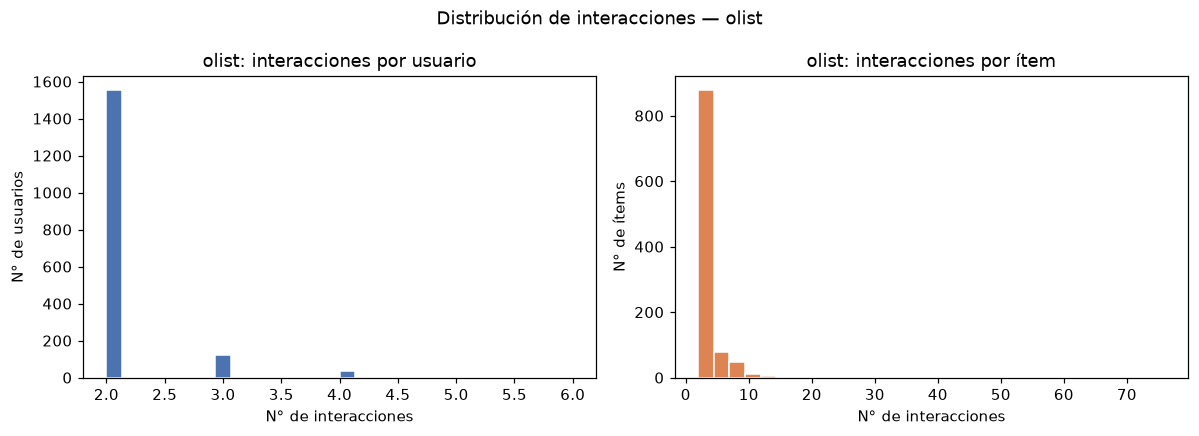

Guardado en: /workspace/graficos/olist_distribucion_interacciones.png


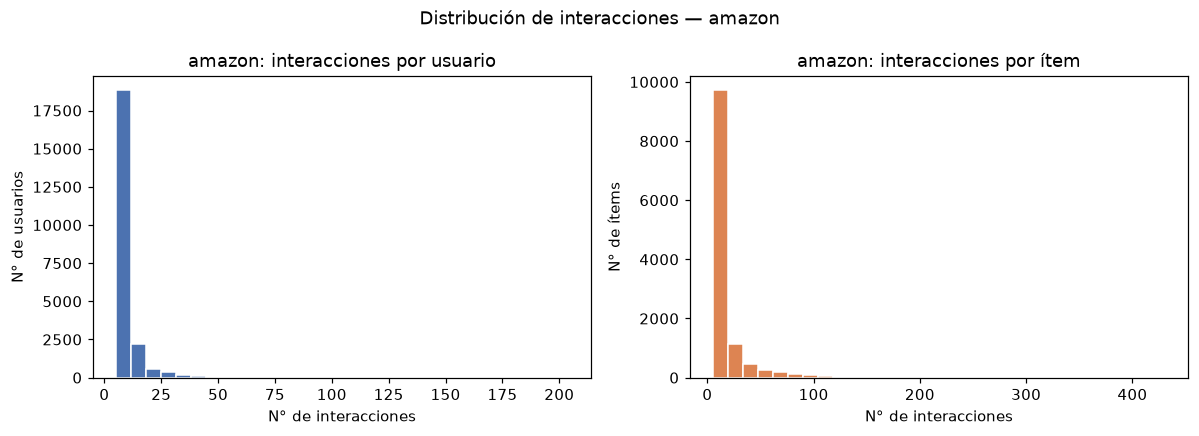

Guardado en: /workspace/graficos/amazon_distribucion_interacciones.png


In [6]:
def graficar_distribucion_interacciones(nombre):
    inter = pd.read_csv(f"data/processed/{nombre}_interacciones.csv")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    conteos_usuario = inter["user_idx"].value_counts()
    axes[0].hist(conteos_usuario, bins=30, color="#4C72B0", edgecolor="white")
    axes[0].set_title(f"{nombre}: interacciones por usuario")
    axes[0].set_xlabel("N° de interacciones")
    axes[0].set_ylabel("N° de usuarios")

    conteos_item = inter["item_idx"].value_counts()
    axes[1].hist(conteos_item, bins=30, color="#DD8452", edgecolor="white")
    axes[1].set_title(f"{nombre}: interacciones por ítem")
    axes[1].set_xlabel("N° de interacciones")
    axes[1].set_ylabel("N° de ítems")

    fig.suptitle(f"Distribución de interacciones — {nombre}")
    fig.tight_layout()
    ruta = os.path.join(GRAF_DIR, f"{nombre}_distribucion_interacciones.png")
    fig.savefig(ruta, dpi=150)
    plt.show()
    print("Guardado en:", ruta)

for nombre in ["olist", "amazon"]:
    graficar_distribucion_interacciones(nombre)


In [7]:
def graficar_resumen_grafo(nombre):
    idmaps = json_lib.load(open(f"data/processed/{nombre}_id_maps.json"))
    edge_index = np.load(f"data/processed/{nombre}_edge_index.npy")

    n_users, n_items = idmaps["n_users"], idmaps["n_items"]
    n_aristas = edge_index.shape[1] // 2  # no dirigido: se guarda ida y vuelta
    densidad = n_aristas / (n_users * n_items)

    print(f"--- {nombre} ---")
    print(f"  usuarios: {n_users:,}")
    print(f"  items: {n_items:,}")
    print(f"  aristas (usuario-item, sin contar ambos sentidos): {n_aristas:,}")
    print(f"  densidad del grafo bipartito: {densidad:.6f}")
    print()

    return {"dataset": nombre, "usuarios": n_users, "items": n_items,
            "aristas": n_aristas, "densidad": densidad}

resumen_grafos = pd.DataFrame([graficar_resumen_grafo(n) for n in ["olist", "amazon"]])
resumen_grafos


--- olist ---
  usuarios: 1,713
  items: 1,035
  aristas (usuario-item, sin contar ambos sentidos): 3,631
  densidad del grafo bipartito: 0.002048

--- amazon ---
  usuarios: 22,363
  items: 12,101
  aristas (usuario-item, sin contar ambos sentidos): 198,502
  densidad del grafo bipartito: 0.000734



,dataset,usuarios,items,aristas,densidad
0,olist,1713,1035,3631,0.002048
1,amazon,22363,12101,198502,0.000734


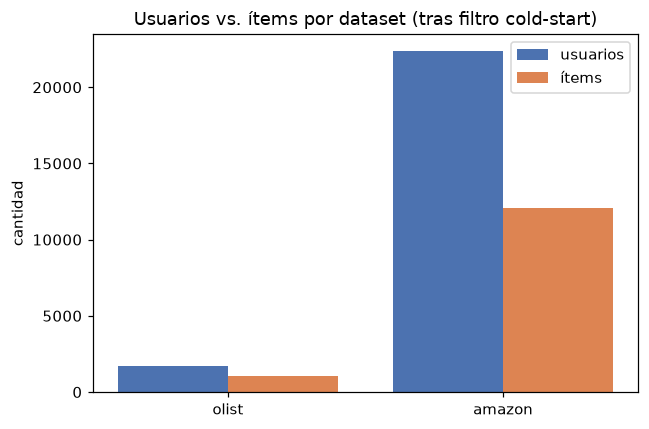

Guardado en: /workspace/graficos/comparacion_usuarios_items.png


In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(resumen_grafos))
ax.bar(x - 0.2, resumen_grafos["usuarios"], width=0.4, label="usuarios", color="#4C72B0")
ax.bar(x + 0.2, resumen_grafos["items"], width=0.4, label="ítems", color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels(resumen_grafos["dataset"])
ax.set_ylabel("cantidad")
ax.set_title("Usuarios vs. ítems por dataset (tras filtro cold-start)")
ax.legend()
fig.tight_layout()
ruta = os.path.join(GRAF_DIR, "comparacion_usuarios_items.png")
fig.savefig(ruta, dpi=150)
plt.show()
print("Guardado en:", ruta)


## 5. Resumen final

Tabla de partición (train/val/test) y usuarios cold-start excluidos, para citar en el informe de avance.

In [9]:
metadatos = pd.read_csv("data/processed/metadatos.csv")
print(metadatos.to_string(index=False))


dataset  interacciones_totales  usuarios  items  train   val  test  usuarios_cold_start_excluidos_de_val_test  seed
  olist                   3631      1713   1035   3309   161   161                                       1552    42
 amazon                 198502     22363  12101 153776 22363 22363                                          0    42


---
**Listo.** Los archivos procesados están en `data/processed/` y los gráficos en `graficos/`.
Estos son los insumos para la Semana 3–4: el grafo (`*_edge_index.npy`) alimenta la rama GNN,
y las secuencias (`*_secuencias.json`) alimentan la rama Transformer.